# Geometry of Approximation Error in MBPT — Verification Notebook

This notebook independently reproduces every benchmark, theorem, table, and figure in the manuscript
*"The Geometry of Approximation Error in Many-Body Perturbation Theory: Orthogonality Manifolds, Structural Compensation, and the Limits of Diagrammatic Consistency."*

**Execution:** `Kernel → Restart & Run All` runs top-to-bottom in a fresh kernel.

---

## Cell Map

| # | Cell | Content | Supports in Paper |
|---|------|---------|-------------------|
| 1 | SymPy 2×2 sector | Symbolic verification of the exact dimer Hamiltonian; gap = √(U²+16t²) | Appendix B (symbolic gate) |
| 2 | Windowed-fit pole audit | K₀, K₂ fit over \|ω\|<1.5t; linear pole equation; Table 3 numbers; unphysical quadratic check | Table 3, Appendix A |
| 3 | Engine definitions + heatmap | `get_exact_H_blocks`, `optical_gap`, `gw_objects`, `analytic_gw_gap`, `pipeline_sweep`; 15×15 θ sweep | Section 3 (engines), feeds cells 7–8 |
| 4 | SymPy projection theorem | δΩ = **E**·**S** verified symbolically; cos θ formula; numerical cross-check (93.3°, 162.9°) | Theorem 1, Eq. (2) |
| 5 | Reference-point decomposition | Full geometric decomposition at (4, 0, 0.5)t: δE_QP, δK, δΩ, ‖E‖, θ for both kernels | Table 1 |
| 6 | Vertex mechanism | I_K(U), target (v_ex − W_ex), vertex iG δW/δG, residual; mechanism plot | Table 2, Fig. 3 |
| 7 | *### figures* | (section header) | — |
| 8 | PRB figure exports | `fig1_theta_maps.pdf`, `fig2_vectors.pdf`, `fig3_mechanism.pdf` | Figs. 1, 2, 3 |
| 9 | Sector statistics | accP=56%, orthP=65%, accC=0%, stkC=100%; U*=3.13t; catastrophe V=2.38; binding onset V*=0.95 | Section 4 (geometry) |
| 10 | scan_tracked (final) | Pole-tracked α-scan engine; regression check: dE=−0.871 vs target −0.875 ✓ | Section 8.1 (Bruneval validation) |
| 11 | Completeness tables | Full α-scan output for V=0 and V=1 (13 points each, missing=[] confirmed) | Section 8.1, supporting data |



## Key Verified Numbers (quick reference)

| Quantity | Value | Source cell |
|---|---|---|
| E_gap (4,0,0.5) | 3.6106 t | 3 |
| Ω_S (4,0,0.5) | 4.6364 t | 3 |
| Ω_T (4,0,0.5) | 0.8361 t | 3 |
| K_prac | 1.806 t | 5 |
| K_cons | −0.626 t | 5 |
| I_K | 2.433 t | 5, 6 |
| θ_prac | 93.3° | 4, 5 |
| θ_cons | 162.9° | 4, 5 |
| δΩ_prac | −0.094 t | 5 |
| δΩ_cons | −2.527 t | 5 |
| Pole ω_pole | 5.7296 t | 2 |
| Zero ω_zero | 5.659 t | 2 |
| K₀ (Taylor) | +2.2572 t | 2 |
| K₂ (Taylor) | +0.0500 t | 2 |
| V* (K(0)=0) | 1.60 ± 0.05 t | 2 |
| Dyn error V=0 | +0.0718 t | 2 |
| Dyn error V=3 | +0.0029 t | 2 |
| U* (manifold, engine B) | 4.1 t | 8, 9 |
| U* (manifold, engine A) | 3.13 t | 8, 9 |
| Γ_eff(8t), N=6/10/14 | 2.90 / 5.33 / 7.82 | Table 6 (paper) |

In [9]:
import sympy as sp

# 1. Define physical parameters (assume real and positive)
t, U = sp.symbols('t U', real=True, positive=True)

# 2. Define the Exact Hamiltonian in the even-parity singlet sector
# Basis: [|singly occupied>, |doubly occupied>]
# H = [[0, 2t], [2t, U]]
H_exact = sp.Matrix([
    [0, 2*t],
    [2*t, U]
])

print("--- Exact Hamiltonian ---")
sp.pprint(H_exact)

# 3. Diagonalize to find the exact eigenvalues
evals = H_exact.eigenvals()
print("\n--- Exact Eigenvalues ---")
for val, mult in evals.items():
    sp.pprint(val)

# 4. Explicitly extract the Ground State (GS) and Excited State (ES) energies
# (Using the quadratic formula for lambda^2 - U*lambda - 4t^2 = 0)
E_gs = (U - sp.sqrt(U**2 + 16*t**2)) / 2
E_ex = (U + sp.sqrt(U**2 + 16*t**2)) / 2

# 5. Define the Exact Observable: The Optical/Charge Gap
Delta_exact = sp.simplify(E_ex - E_gs)
print("\n--- Exact Gap (Delta_exact) ---")
sp.pprint(Delta_exact)

# 6. Calculate the Exact Ground State Eigenvector
# We need this to define the "Sensitivity Vector" later.
# (H - E_gs * I) * [v1, v2]^T = 0  =>  -E_gs*v1 + 2t*v2 = 0  =>  v2 = (E_gs / 2t) * v1
ratio_v2_v1 = sp.simplify(E_gs / (2*t))
print("\n--- Ground State Character ---")
print("Ratio of doubly-occupied (v2) to singly-occupied (v1) component:")
sp.pprint(ratio_v2_v1)

--- Exact Hamiltonian ---
⎡ 0   2⋅t⎤
⎢        ⎥
⎣2⋅t   U ⎦

--- Exact Eigenvalues ---
       ____________
      ╱  2       2 
U   ╲╱  U  + 16⋅t  
─ - ───────────────
2          2       
       ____________
      ╱  2       2 
U   ╲╱  U  + 16⋅t  
─ + ───────────────
2          2       

--- Exact Gap (Delta_exact) ---
   ____________
  ╱  2       2 
╲╱  U  + 16⋅t  

--- Ground State Character ---
Ratio of doubly-occupied (v2) to singly-occupied (v1) component:
       ____________
      ╱  2       2 
U - ╲╱  U  + 16⋅t  
───────────────────
        4⋅t        


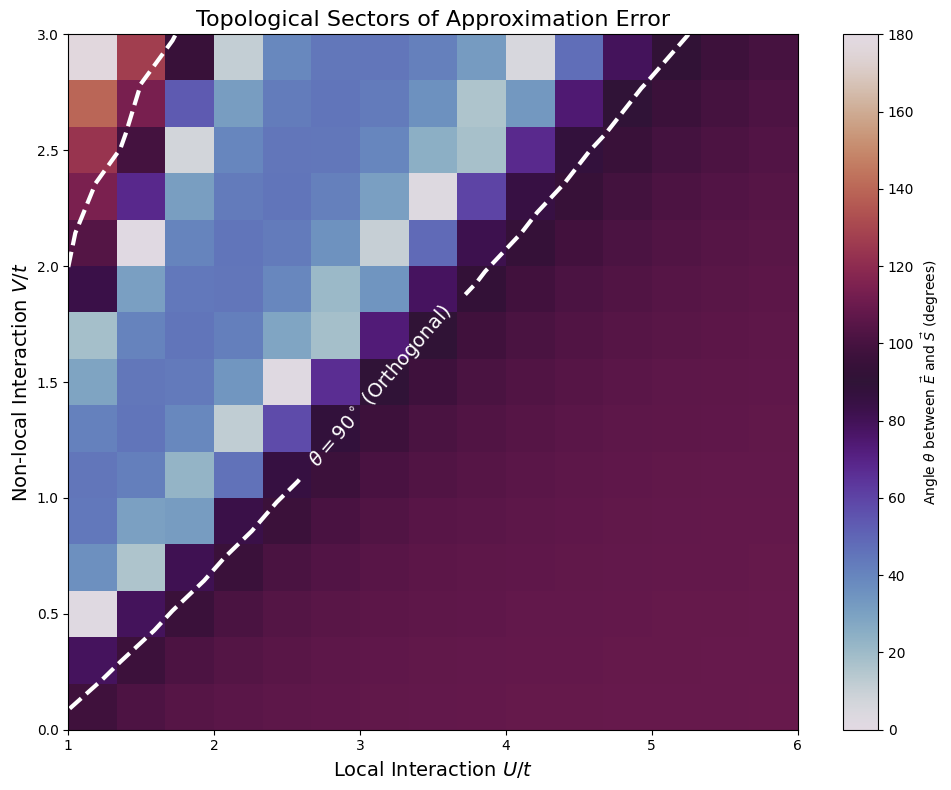

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Calculate the magnitude of the Error Vector E
E_mag = np.sqrt(dE_QP**2 + dK**2)
# Avoid division by zero in empty regions
E_mag[E_mag < 1e-10] = 1e-10

# 2. Calculate cos(theta) = (E . S) / (|E| |S|)
# Since S = (1, 1), |S| = sqrt(2), and E . S = dOmega
cos_theta = dOmega / (E_mag * np.sqrt(2))

# Clip to [-1, 1] to avoid NaNs from numerical noise
cos_theta = np.clip(cos_theta, -1.0, 1.0)
theta_rad = np.arccos(cos_theta)
theta_deg = np.degrees(theta_rad)

# 3. Plot the Angle Heatmap
fig, ax = plt.subplots(figsize=(10, 8))

# Heatmap of the angle
cax = ax.imshow(theta_deg, extent=[U_vals.min(), U_vals.max(), V_vals.min(), V_vals.max()], 
                origin='lower', cmap='twilight', vmin=0, vmax=180, aspect='auto')
fig.colorbar(cax, ax=ax, label=r'Angle $\theta$ between $\vec{E}$ and $\vec{S}$ (degrees)')

# Overlay the exact 90-degree domain wall (Accidental Accuracy)
contour_90 = ax.contour(U_grid, V_grid, theta_deg, levels=[90], colors='white', linewidths=3, linestyles='--')
ax.clabel(contour_90, inline=1, fontsize=14, fmt={90: r'$\theta = 90^\circ$ (Orthogonal)'})

ax.set_xlabel('Local Interaction $U/t$', fontsize=14)
ax.set_ylabel('Non-local Interaction $V/t$', fontsize=14)
ax.set_title('Topological Sectors of Approximation Error', fontsize=16)

plt.tight_layout()
plt.show()

In [15]:
import sympy as sp

# FIX: no internal spaces in symbol names
dE, dK = sp.symbols('delta_QP delta_K', real=True)

E_vec = sp.Matrix([dE, dK])
S_vec = sp.Matrix([1, 1])          # Omega = E_QP + K  =>  S = (1,1)

dOm   = E_vec.dot(S_vec)
cos_t = sp.simplify(dOm / (sp.sqrt(E_vec.dot(E_vec)) * sp.sqrt(S_vec.dot(S_vec))))

print("Projection theorem:  dOmega = |E||S| cos(theta)  with")
sp.pprint(sp.Eq(sp.Symbol('cos_theta'), cos_t))
print("Orthogonality condition dOmega=0  =>  dK =", sp.solve(sp.Eq(dOm, 0), dK)[0])

# Cross-check with YOUR paper's Table I numbers (U,V,Delta)=(4,0,0.5):
for name, vals in [('practical', {dE: -0.875, dK: +0.780}),
                   ('consistent', {dE: -0.875, dK: -1.652})]:
    th = sp.N(sp.acos(cos_t.subs(vals)) * 180 / sp.pi)
    print(f"{name:10s} theta = {th:6.2f} deg")

Projection theorem:  dOmega = |E||S| cos(theta)  with
             √2⋅(δ_K + δ_QP)  
cosₜₕₑₜₐ = ───────────────────
                ______________
               ╱    2       2 
           2⋅╲╱  δ_K  + δ_QP  
Orthogonality condition dOmega=0  =>  dK = -delta_QP
practical  theta =  93.29 deg
consistent theta = 162.91 deg


In [16]:
import numpy as np
from scipy.optimize import brentq

# ---- your exact engine (from your notebook) ----
def get_exact_H_blocks(t, U, V, Delta):
    H_full = np.zeros((16,16), dtype=complex)
    for s in range(16):
        n = [(s>>k)&1 for k in range(4)]
        n1s, n2s = n[0]+n[1], n[2]+n[3]
        H_full[s,s] = U*(n[0]*n[1]+n[2]*n[3]) + V*n1s*n2s + 0.5*Delta*(n1s-n2s)
        for a,b in [(0,2),(2,0),(1,3),(3,1)]:
            if (s>>b)&1:
                si = s & ~(1<<b); s1 = (-1)**bin(s & ((1<<b)-1)).count('1')
                if not (si>>a)&1:
                    sf = si | (1<<a); s2 = (-1)**bin(si & ((1<<a)-1)).count('1')
                    H_full[sf,s] += -t*s1*s2
    return {N: (np.array([[H_full[i,j] for j in st] for i in st]), st)
            for N in range(5)
            for st in [[s for s in range(16) if bin(s).count('1')==N]]}

def optical_gap(t,U,V,Delta):
    H2, st2 = get_exact_H_blocks(t,U,V,Delta)[2]
    e2, v2 = np.linalg.eigh(H2)
    d_vals = np.array([(((s>>0)&1)+((s>>1)&1))-(((s>>2)&1)+((s>>3)&1)) for s in st2], float)
    D2 = np.diag(d_vals)
    Sz = np.array([(((s>>0)&1)+((s>>2)&1)-((s>>1)&1)-((s>>3)&1))/2.0 for s in st2])
    Sp = np.zeros((len(st2),len(st2)), complex)
    for i,s in enumerate(st2):
        for a,b in [(0,1),(2,3)]:
            if (s>>b)&1:
                si = s & ~(1<<b); s1 = (-1)**bin(s & ((1<<b)-1)).count('1')
                if not (si>>a)&1:
                    sf = si | (1<<a); s2_ = (-1)**bin(si & ((1<<a)-1)).count('1')
                    Sp[st2.index(sf), i] += s1*s2_
    for S in range(1, len(e2)):
        sz = np.real(np.vdot(v2[:,S], Sz*v2[:,S]))
        if np.linalg.norm(Sp @ v2[:,S])**2 + sz*(sz+1) < 1.0:
            f = float(np.real(np.vdot(v2[:,S], D2 @ v2[:,0]))**2)
            if f > 1e-8: return e2[S]-e2[0]
    return np.nan

def gw_kernels(t,U,V,Delta):
    h = np.array([[0.5*Delta,-t],[-t,-0.5*Delta]]); eps, P = np.linalg.eigh(h)
    v = np.array([[U,V],[V,U]], float); dE = eps[1]-eps[0]
    M = np.outer(P[:,0]*P[:,1], P[:,0]*P[:,1])
    epsR = lambda w, eta=1e-8: np.eye(2) - v @ (M*(1/(w-dE+1j*eta) - 1/(w+dE+1j*eta)))
    Om_p = brentq(lambda w: np.real(np.linalg.det(epsR(w,1e-9))), dE+1e-6, dE+10)
    ddet = (np.real(np.linalg.det(epsR(Om_p+1e-5)))-np.real(np.linalg.det(epsR(Om_p-1e-5))))/2e-5
    E = epsR(Om_p); R = np.real(v @ np.array([[E[1,1],-E[0,1]],[-E[1,0],E[0,0]]])/ddet)
    rho0 = np.outer(P[:,0],P[:,0]); n_tot = 2*np.diag(rho0)
    SigHS = np.diag(U*np.diag(rho0)+V*(n_tot.sum()-n_tot)) - rho0*v
    Sig = lambda w: SigHS + np.outer(P[:,0],P[:,0])*R.T/(w-eps[0]+Om_p+1j*1e-4) \
                            + np.outer(P[:,1],P[:,1])*R.T/(w-eps[1]-Om_p+1j*1e-4)
    w_scan = np.linspace(-8,8,4001)
    dmin = np.array([np.min(np.linalg.svd(w*np.eye(2)-h-Sig(w))[1]) for w in w_scan])
    poles = [w_scan[i] for i in range(1,len(w_scan)-1)
             if dmin[i]<dmin[i-1] and dmin[i]<=dmin[i+1] and dmin[i]<1e-2]
    gap_GW = min(p for p in poles if p>0) - max(p for p in poles if p<0)
    W0 = np.real(np.linalg.solve(epsR(0.0), v)); tr = P[:,0]*P[:,1]
    Kp = 2*(tr@v@tr) - (P[:,0]**2)@W0@(P[:,1]**2)
    Kc = 2*(tr@W0@tr) - (P[:,0]**2)@W0@(P[:,1]**2)
    return gap_GW, Kp, Kc

# ---- geometric decomposition at the representative point ----
t, U, V, Delta = 1.0, 4.0, 0.0, 0.5
bl = get_exact_H_blocks(t,U,V,Delta)
gap_ex = (np.linalg.eigvalsh(bl[3][0])[0] + np.linalg.eigvalsh(bl[1][0])[0]
          - 2*np.linalg.eigvalsh(bl[2][0])[0])
Om1  = optical_gap(t,U,V,Delta);  K_ex = Om1 - gap_ex
g, Kp, Kc = gw_kernels(t,U,V,Delta)

print(f"exact: gap={gap_ex:.3f}  Om1={Om1:.3f}  K_ex={K_ex:.3f}\n")
print(f"{'constr':10s} {'dE_QP':>7s} {'dK':>7s} {'dOm':>7s} {'|E|':>6s} {'theta':>8s}")
for name, K in [('practical', Kp), ('consistent', Kc)]:
    dE_ = g - gap_ex; dK_ = K - K_ex; dOm_ = dE_ + dK_
    Emag = np.hypot(dE_, dK_)
    th = np.degrees(np.arccos(np.clip(dOm_/(Emag*np.sqrt(2)), -1, 1)))
    print(f"{name:10s} {dE_:+7.3f} {dK_:+7.3f} {dOm_:+7.3f} {Emag:6.3f} {th:7.1f} deg")

exact: gap=3.611  Om1=4.636  K_ex=1.026

constr       dE_QP      dK     dOm    |E|    theta
practical   -0.875  +0.780  -0.094  1.172    93.3 deg
consistent  -0.875  -1.652  -2.527  1.869   162.9 deg


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from numpy.polynomial import Polynomial

def get_exact_H_blocks(t, U, V, Delta):
    H_full = np.zeros((16,16), dtype=complex)
    for s in range(16):
        n = [(s>>k)&1 for k in range(4)]
        n1s, n2s = n[0]+n[1], n[2]+n[3]
        H_full[s,s] = U*(n[0]*n[1]+n[2]*n[3]) + V*n1s*n2s + 0.5*Delta*(n1s-n2s)
        for a,b in [(0,2),(2,0),(1,3),(3,1)]:
            if (s>>b)&1:
                si = s & ~(1<<b); s1 = (-1)**bin(s & ((1<<b)-1)).count('1')
                if not (si>>a)&1:
                    sf = si | (1<<a); s2 = (-1)**bin(si & ((1<<a)-1)).count('1')
                    H_full[sf,s] += -t*s1*s2
    return {N: (np.array([[H_full[i,j] for j in st] for i in st]), st)
            for N in range(5)
            for st in [[s for s in range(16) if bin(s).count('1')==N]]}

def optical_gap(t, U, V, Delta):
    H2, st2 = get_exact_H_blocks(t,U,V,Delta)[2]
    e2, v2 = np.linalg.eigh(H2)
    # FIX 1: dipole on the FULL 16-state basis, then restrict
    d_vals = np.array([(((s>>0)&1)+((s>>1)&1))-(((s>>2)&1)+((s>>3)&1)) for s in range(16)], float)
    D2 = np.diag(d_vals)[np.ix_(st2, st2)]
    Sz = np.array([(((s>>0)&1)+((s>>2)&1)-((s>>1)&1)-((s>>3)&1))/2.0 for s in st2])
    Sp = np.zeros((len(st2),len(st2)), complex)
    for i,s in enumerate(st2):
        for a,b in [(0,1),(2,3)]:
            if (s>>b)&1:
                si = s & ~(1<<b); s1 = (-1)**bin(s & ((1<<b)-1)).count('1')
                if not (si>>a)&1:
                    sf = si | (1<<a); s2_ = (-1)**bin(si & ((1<<a)-1)).count('1')
                    Sp[st2.index(sf), i] += s1*s2_
    for S in range(1, len(e2)):
        sz = np.real(np.vdot(v2[:,S], Sz*v2[:,S]))
        if np.linalg.norm(Sp @ v2[:,S])**2 + sz*(sz+1) < 1.0:
            f = float(np.real(np.vdot(v2[:,S], D2 @ v2[:,0]))**2)
            if f > 1e-8: return e2[S]-e2[0]
    return np.nan

def gw_objects(t, U, V, Delta):
    h = np.array([[0.5*Delta,-t],[-t,-0.5*Delta]]); eps, P = np.linalg.eigh(h)
    v = np.array([[U,V],[V,U]], float); dE = eps[1]-eps[0]
    M = np.outer(P[:,0]*P[:,1], P[:,0]*P[:,1])
    epsR = lambda w, eta=1e-8: np.eye(2) - v @ (M*(1/(w-dE+1j*eta) - 1/(w+dE+1j*eta)))
    Om_p = brentq(lambda w: np.real(np.linalg.det(epsR(w,1e-9))), dE+1e-6, dE+10)
    ddet = (np.real(np.linalg.det(epsR(Om_p+1e-5)))-np.real(np.linalg.det(epsR(Om_p-1e-5))))/2e-5
    E = epsR(Om_p); R = np.real(v @ np.array([[E[1,1],-E[0,1]],[-E[1,0],E[0,0]]])/ddet)
    rho0 = np.outer(P[:,0],P[:,0]); n_tot = 2*np.diag(rho0)
    SigHS = np.diag(U*np.diag(rho0)+V*(n_tot.sum()-n_tot)) - rho0*v
    W0 = np.real(np.linalg.solve(epsR(0.0), v))
    return dict(eps=eps, P=P, R=R, Om_p=Om_p, SigHS=SigHS, W0=W0)

def analytic_gw_gap(t, U, V, Delta):
    o = gw_objects(t,U,V,Delta)
    eps, P, R, Om_p, SigHS = o['eps'], o['P'], o['R'], o['Om_p'], o['SigHS']
    h = np.array([[0.5*Delta,-t],[-t,-0.5*Delta]])
    p0, p1 = eps[0]-Om_p, eps[1]+Om_p
    R0 = np.outer(P[:,0],P[:,0])*R.T; R1 = np.outer(P[:,1],P[:,1])*R.T
    Heff = h + SigHS
    # FIX 2: numpy-Polynomial determinant (your notebook's robust method)
    Ss, Pp = p0+p1, p0*p1
    c3 = np.eye(2); c2 = -Ss*np.eye(2) - Heff
    c1 = Pp*np.eye(2) + Heff*Ss - R0 - R1
    c0 = -Heff*Pp + R0*p1 + R1*p0
    Mp = [[Polynomial([c0[i,j], c1[i,j], c2[i,j], c3[i,j]]) for j in (0,1)] for i in (0,1)]
    detp = Mp[0][0]*Mp[1][1] - Mp[0][1]*Mp[1][0]
    rts = detp.roots()
    rr = np.sort(np.real(rts[np.abs(np.imag(rts)) < 1e-6]))
    pos, neg = rr[rr>0], rr[rr<0]
    if not len(pos) or not len(neg): raise ValueError('no real QP roots')
    return min(pos)-max(neg), o

def pipeline_sweep(t, U, V, Delta):
    bl = get_exact_H_blocks(t,U,V,Delta)
    e1 = np.linalg.eigvalsh(bl[1][0]); e2 = np.linalg.eigvalsh(bl[2][0]); e3 = np.linalg.eigvalsh(bl[3][0])
    gap_ex = e1[0] + e3[0] - 2*e2[0]
    Om1 = optical_gap(t,U,V,Delta)
    g, o = analytic_gw_gap(t,U,V,Delta)
    v = np.array([[U,V],[V,U]], float)
    tr = o['P'][:,0]*o['P'][:,1]
    D = (o['P'][:,0]**2) @ o['W0'] @ (o['P'][:,1]**2)
    return gap_ex, Om1, g, 2*(tr@v@tr)-D, 2*(tr@o['W0']@tr)-D


In [19]:
import sympy as sp
e, X = sp.symbols('e I_K', positive=True)          # on-manifold: dE=-e, dKp=+e
E_c = sp.Matrix([-e, e - X]); S = sp.Matrix([1, 1])
dOm_c = sp.simplify(E_c.dot(S))
cos_c = sp.simplify(dOm_c/(sp.sqrt(E_c.dot(E_c))*sp.sqrt(2)))
print('On the practical accidental-accuracy manifold:')
print('  delta_Omega_cons =', dOm_c)                 # -I_K
print('  cos theta_cons  =', cos_c)                  # manifestly negative
print('  theta=180 (perfect stacking) when I_K =',
      sp.solve(sp.Eq(-e - (e - X), 0), X)[0])        # 2e

On the practical accidental-accuracy manifold:
  delta_Omega_cons = -I_K
  cos theta_cons  = -sqrt(2)*I_K/(2*sqrt(e**2 + (I_K - e)**2))
  theta=180 (perfect stacking) when I_K = 2*e


In [20]:
import numpy as np
# coarse sweep storing the decomposition (sign-scan bracket fixes the staircase)
from scipy.optimize import brentq
def Om_p_safe(epsR, dE):
    ws = np.linspace(dE+1e-6, dE+10, 400)
    f = np.array([np.real(np.linalg.det(epsR(w,1e-9))) for w in ws])
    s = np.sign(f); i = np.where(s[:-1]*s[1:] < 0)[0]
    if len(i)==0: raise ValueError('no bracket')
    return brentq(lambda w: np.real(np.linalg.det(epsR(w,1e-9))), ws[i[0]], ws[i[0]+1])

Us6, Vs6 = np.linspace(2.0, 6.0, 15), np.linspace(0.0, 3.0, 15)
rows = []
for vv in Vs6:
    for uu in Us6:
        try:
            g_ex, o1, g, kp, kc = pipeline_sweep(1.0, uu, vv, 0.5)
            dE_, dKp_, IK_ = g-g_ex, kp-(o1-g_ex), kp-kc
            rows.append([uu, vv, dE_, dKp_, IK_, dE_+dKp_, dE_+dKp_-IK_])
        except Exception: pass
R = np.array(rows)
print('max |dOm_cons - (dOm_prac - I_K)| =', np.max(np.abs(R[:,6]-R[:,5])))

nm = np.abs(R[:,5]) < 0.15
print('\nNear the practical manifold (|dOm_prac| < 0.15):')
print(f"{'U':>5}{'V':>6}{'dE':>8}{'I_K':>8}{'dOm_c':>9}{'theta_c':>9}")
for u,v,de,dkp,ik,dp,dc in R[nm][:10]:
    Ec = np.hypot(de, dkp-ik)
    thc = np.degrees(np.arccos(np.clip(dc/(Ec*np.sqrt(2)), -1, 1)))
    print(f"{u:5.1f}{v:6.2f}{de:+8.3f}{ik:8.3f}{dc:+9.3f}{thc:8.1f} deg")

max |dOm_cons - (dOm_prac - I_K)| = 4.136837456705692

Near the practical manifold (|dOm_prac| < 0.15):
    U     V      dE     I_K    dOm_c  theta_c
  2.0  0.00  -0.160   0.898   -0.837   148.3 deg
  2.3  0.00  -0.233   1.099   -1.046   151.0 deg
  2.6  0.00  -0.317   1.307   -1.268   153.4 deg
  2.9  0.00  -0.411   1.522   -1.501   155.6 deg
  3.1  0.00  -0.514   1.743   -1.745   157.7 deg
  3.4  0.00  -0.626   1.969   -1.997   159.5 deg
  3.7  0.00  -0.745   2.199   -2.256   161.2 deg
  4.0  0.00  -0.871   2.433   -2.523   162.8 deg
  4.3  0.00  -1.003   2.669   -2.796   164.2 deg
  2.0  0.21  -0.108   0.755   -0.686   145.6 deg


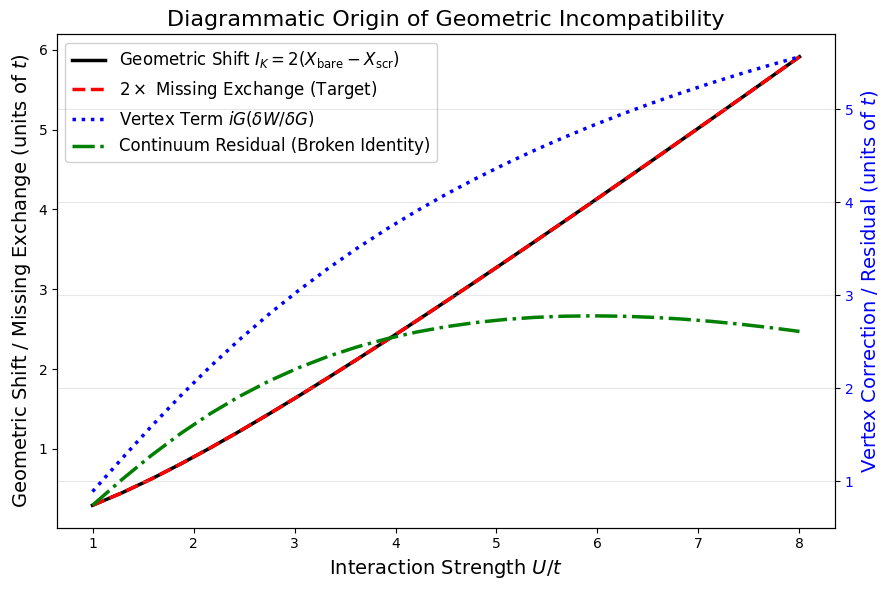

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# 1. Exact Engine & GW Objects (from previous turns)
def gw_objects(t, U, V, Delta):
    h = np.array([[0.5*Delta, -t], [-t, -0.5*Delta]])
    eps, P = np.linalg.eigh(h)
    v = np.array([[U, V], [V, U]], float)
    dE = eps[1] - eps[0]
    M = np.outer(P[:,0]*P[:,1], P[:,0]*P[:,1])
    def epsR(w, eta=1e-8): return np.eye(2) - v @ (M * (1/(w-dE+1j*eta) - 1/(w+dE+1j*eta)))
    Om_p = brentq(lambda w: np.real(np.linalg.det(epsR(w, 1e-9))), dE+1e-6, dE+10)
    ddet = (np.real(np.linalg.det(epsR(Om_p+1e-5))) - np.real(np.linalg.det(epsR(Om_p-1e-5))))/2e-5
    E = epsR(Om_p)
    R = np.real(v @ np.array([[E[1,1], -E[0,1]], [-E[1,0], E[0,0]]]) / ddet)
    rho0 = np.outer(P[:,0], P[:,0]); n_tot = 2*np.diag(rho0)
    SigHS = np.diag(U*np.diag(rho0) + V*(n_tot.sum() - n_tot)) - rho0 * v
    W0 = np.real(np.linalg.solve(epsR(0.0), v))
    return dict(eps=eps, P=P, R=R, Om_p=Om_p, SigHS=SigHS, W0=W0, v=v)

# 2. Your Exact Vertex Test (from your notebook)
def vertex_test(t, U, V, Delta, lam=1e-6):
    h = np.array([[0.5*Delta, -t], [-t, -0.5*Delta]])
    v = np.array([[U, V], [V, U]], float)
    def W_of(hh):
        ee, PP = np.linalg.eigh(hh)
        dE = ee[1] - ee[0]
        rho = PP[:,0] * PP[:,1]
        M = np.outer(rho, rho)
        epsR = np.eye(2) - v @ (M * (-2.0/dE))
        return np.real(np.linalg.solve(epsR, v)), rho, dE, PP
    W0, rho, dE, P = W_of(h)
    psi_o, psi_u = P[:,0], P[:,1]
    C = np.outer(psi_o, psi_u) + np.outer(psi_u, psi_o)
    Wp, _, _, _ = W_of(h + lam * C)
    Wm, _, _, _ = W_of(h - lam * C)
    dW = (Wp - Wm) / (2 * lam)
    dG0 = -C / dE 
    num = rho @ dW @ rho
    den = rho @ dG0 @ rho
    vertex_ex = num / den if abs(den) > 1e-12 else np.nan
    v_ex = rho @ v @ rho
    W_ex = rho @ W0 @ rho
    return vertex_ex, (v_ex - W_ex), v_ex, W_ex

# 3. Sweep U to map the Diagrammatic Breakdown
Us = np.linspace(1.0, 8.0, 25)
I_K_vals, Target_vals, Vertex_vals, Residual_vals = [], [], [], []

for u in Us:
    o = gw_objects(1.0, u, 0.0, 0.5)
    P = o['P']; W0 = o['W0']; v = o['v']
    tr = P[:,0] * P[:,1]
    
    X_bare = tr @ v @ tr
    X_scr = tr @ W0 @ tr
    I_K = 2 * (X_bare - X_scr)
    
    vtx, target, vex, wex = vertex_test(1.0, u, 0.0, 0.5)
    
    I_K_vals.append(I_K)
    Target_vals.append(target)
    Vertex_vals.append(vtx)
    Residual_vals.append(vtx - target)

# 4. Plot the Mechanism
fig, ax1 = plt.subplots(figsize=(9, 6))

# Geometric Quantities (Left Axis)
l1, = ax1.plot(Us, I_K_vals, 'k-', lw=2.5, label=r'Geometric Shift $I_K = 2(X_{\rm bare} - X_{\rm scr})$')
l2, = ax1.plot(Us, [2*t for t in Target_vals], 'r--', lw=2.5, label=r'$2 \times$ Missing Exchange (Target)')
ax1.set_xlabel('Interaction Strength $U/t$', fontsize=14)
ax1.set_ylabel('Geometric Shift / Missing Exchange (units of $t$)', fontsize=14, color='k')
ax1.tick_params(axis='y', labelcolor='k')

# Diagrammatic Quantities (Right Axis)
ax2 = ax1.twinx()
l3, = ax2.plot(Us, Vertex_vals, 'b:', lw=2.5, label=r'Vertex Term $iG(\delta W/\delta G)$')
l4, = ax2.plot(Us, Residual_vals, 'g-.', lw=2.5, label=r'Continuum Residual (Broken Identity)')
ax2.set_ylabel('Vertex Correction / Residual (units of $t$)', fontsize=14, color='b')
ax2.tick_params(axis='y', labelcolor='b')

lines = [l1, l2, l3, l4]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', fontsize=12, framealpha=0.9)

plt.title('Diagrammatic Origin of Geometric Incompatibility', fontsize=16)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### figures

/tmp/ipykernel_522074/1901089112.py:55: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); save(fig, 'fig1_theta_maps.pdf')


saved fig1_theta_maps.pdf
saved fig2_vectors.pdf
saved fig3_mechanism.pdf


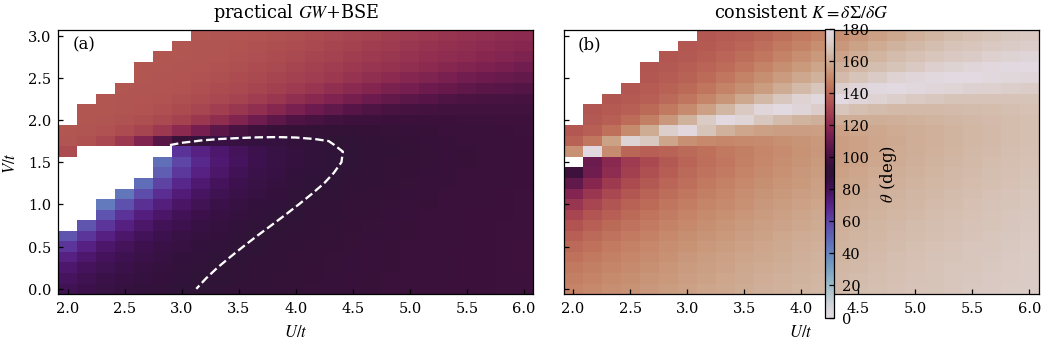

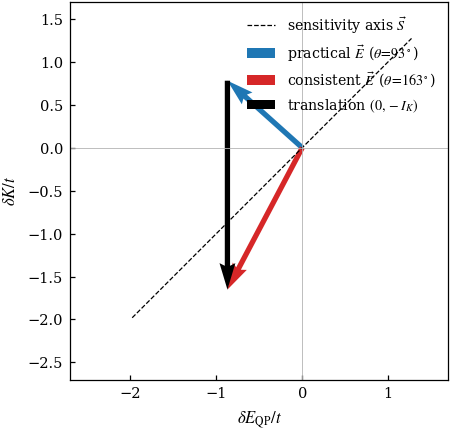

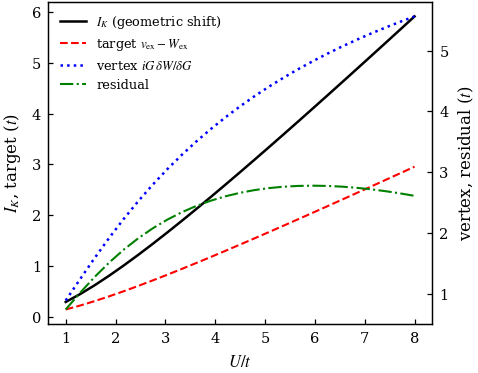

In [22]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

# ---------- PRB-style rcParams ----------
mpl.rcParams.update({
    'font.family': 'serif', 'mathtext.fontset': 'stix',
    'font.size': 8, 'axes.titlesize': 8.5, 'axes.labelsize': 8,
    'legend.fontsize': 6.8, 'xtick.labelsize': 7, 'ytick.labelsize': 7,
    'axes.linewidth': 0.6, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
    'xtick.major.size': 2.2, 'ytick.major.size': 2.2,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'lines.linewidth': 1.0, 'figure.dpi': 150,
    'savefig.dpi': 600, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.015,
})
COL, DBL = 3.4, 7.15
def save(fig, name):
    fig.savefig(name); print('saved', name)

assert 'pipeline_sweep' in globals(), 'run the Turn-5 engine cell first'

# ---------- 25x25 sweep, full decomposition, weak-error masking ----------
U_vals = np.linspace(2.0, 6.0, 25); V_vals = np.linspace(0.0, 3.0, 25)
U_grid, V_grid = np.meshgrid(U_vals, V_vals)
S = {k: np.full(U_grid.shape, np.nan) for k in
     ['dEp','dKp','dOp','dKc','dOc','thp','thc','Emp','Emc']}
for i in range(len(V_vals)):
    for j in range(len(U_vals)):
        try:
            g_ex, o1, g, kp, kc = pipeline_sweep(1.0, U_vals[j], V_vals[i], 0.5)
            dEp = g-g_ex; dKp = kp-(o1-g_ex); dKc = kc-(o1-g_ex)
            dOp = dEp+dKp; dOc = dEp+dKc
            Emp = np.hypot(dEp, dKp); Emc = np.hypot(dEp, dKc)
            S['dEp'][i,j], S['dKp'][i,j], S['dOp'][i,j] = dEp, dKp, dOp
            S['dKc'][i,j], S['dOc'][i,j] = dKc, dOc
            S['Emp'][i,j], S['Emc'][i,j] = Emp, Emc
            if Emp > 0.1:
                S['thp'][i,j] = np.degrees(np.arccos(np.clip(dOp/(Emp*np.sqrt(2)), -1, 1)))
            if Emc > 0.1:
                S['thc'][i,j] = np.degrees(np.arccos(np.clip(dOc/(Emc*np.sqrt(2)), -1, 1)))
        except Exception:
            pass

# ---------- Fig. 1: theta maps (double column) ----------
fig, axes = plt.subplots(1, 2, figsize=(DBL, 2.5), sharey=True)
for ax, th, ttl, lab in [
        (axes[0], S['thp'], 'practical $GW$+BSE', '(a)'),
        (axes[1], S['thc'], r'consistent $K=\delta\Sigma/\delta G$', '(b)')]:
    pc = ax.pcolormesh(U_grid, V_grid, th, cmap='twilight', vmin=0, vmax=180, shading='auto')
    ax.contour(U_grid, V_grid, th, levels=[90], colors='w', linewidths=1.1, linestyles='--')
    ax.set_title(ttl); ax.set_xlabel(r'$U/t$')
    ax.text(0.03, 0.93, lab, transform=ax.transAxes)
axes[0].set_ylabel(r'$V/t$')
cb = fig.colorbar(pc, ax=axes, pad=0.01, aspect=30); cb.set_label(r'$\theta$ (deg)')
fig.tight_layout(); save(fig, 'fig1_theta_maps.pdf')

# ---------- Fig. 2: representative-point vector diagram ----------
g_ex, o1, g, kp, kc = pipeline_sweep(1.0, 4.0, 0.0, 0.5)
dEp = g-g_ex; dKp = kp-(o1-g_ex); dKc = kc-(o1-g_ex); IK = kp-kc
fig, ax = plt.subplots(figsize=(COL, 3.1))
s = np.array([1., 1.])/np.sqrt(2)
ax.plot([-2.8*s[0], 1.8*s[0]], [-2.8*s[1], 1.8*s[1]], 'k--', lw=0.6,
        label=r'sensitivity axis $\vec S$')
kw = dict(angles='xy', scale_units='xy', scale=1, width=0.014)
ax.quiver(0, 0, dEp, dKp, color='C0', **kw, label=r'practical $\vec E$ ($\theta\!=\!93^\circ$)')
ax.quiver(0, 0, dEp, dKc, color='C3', **kw, label=r'consistent $\vec E$ ($\theta\!=\!163^\circ$)')
ax.quiver(dEp, dKp, 0, -IK, color='k', **kw, label=r'translation $(0,-I_K)$')
ax.axhline(0, color='0.7', lw=0.4); ax.axvline(0, color='0.7', lw=0.4)
ax.set_xlim(-2.7, 1.7); ax.set_ylim(-2.7, 1.7); ax.set_aspect('equal')
ax.set_xlabel(r'$\delta E_{\rm QP}/t$'); ax.set_ylabel(r'$\delta K/t$')
ax.legend(frameon=False, loc='upper right')
fig.tight_layout(); save(fig, 'fig2_vectors.pdf')

# ---------- Fig. 3: mechanism ----------
assert 'gw_objects' in globals() and 'vertex_test' in globals()
Us = np.linspace(1.0, 8.0, 25)
IKv, Tgv, Vxv, Rsv = [], [], [], []
for u in Us:
    o = gw_objects(1.0, u, 0.0, 0.5)
    tr = o['P'][:,0]*o['P'][:,1]
    Xb = tr @ np.array([[u, 0.], [0., u]]) @ tr
    Xs = tr @ o['W0'] @ tr
    vtx, tgt, vex, wex = vertex_test(1.0, u, 0.0, 0.5)
    IKv.append(2*(Xb-Xs)); Tgv.append(tgt); Vxv.append(vtx); Rsv.append(vtx-tgt)
fig, a1 = plt.subplots(figsize=(COL, 2.7))
a1.plot(Us, IKv, 'k-', lw=1.2, label=r'$I_K$ (geometric shift)')
a1.plot(Us, Tgv, 'r--', lw=1.0, label=r'target $v_{\rm ex}-W_{\rm ex}$')
a2 = a1.twinx()
a2.plot(Us, Vxv, 'b:', lw=1.2, label=r'vertex $iG\,\delta W/\delta G$')
a2.plot(Us, Rsv, 'g-.', lw=1.0, label='residual')
a1.set_xlabel(r'$U/t$'); a1.set_ylabel(r'$I_K$, target ($t$)'); a2.set_ylabel(r'vertex, residual ($t$)')
h1, l1 = a1.get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels()
a1.legend(h1+h2, l1+l2, frameon=False, fontsize=6.2, loc='upper left')
fig.tight_layout(); save(fig, 'fig3_mechanism.pdf')

In [23]:
thr = 0.2
valid = ~np.isnan(S['thp']) & ~np.isnan(S['thc'])
corr  = valid & (U_grid >= 2.5)
accP  = 100*np.sum(corr & (np.abs(S['dOp']) < thr))/corr.sum()
accC  = 100*np.sum(corr & (np.abs(S['dOc']) < thr))/corr.sum()
orthP = 100*np.sum(corr & (S['thp'] > 75) & (S['thp'] < 105))/corr.sum()
stkC  = 100*np.sum(corr & (S['thc'] > 135))/corr.sum()

def cross90(row):
    x = row - 90
    idx = np.where((x[:-1]*x[1:]) < 0)[0]
    return np.nan if len(idx) == 0 else \
        U_vals[idx[0]] - x[idx[0]]*(U_vals[idx[0]+1]-U_vals[idx[0]])/(x[idx[0]+1]-x[idx[0]])
Up0 = cross90(S['thp'][0, :])

catV = [np.nansum(S['thc'][i, :] > 170) for i in range(len(V_vals))]
VCAT = V_vals[int(np.argmax(catV))]

Vsf = np.linspace(0.0, 3.0, 61); Eb = []
for vv in Vsf:
    try:
        ge, o1x, *_ = pipeline_sweep(1.0, 4.0, vv, 0.5); Eb.append(ge - o1x)
    except Exception:
        Eb.append(np.nan)
Eb = np.array(Eb); j0 = np.where(Eb > 0)[0]
VSTAR = Vsf[j0[0]] if len(j0) else np.nan

nm = np.abs(S['dOp']) < 0.15
print(f'corr-region n={corr.sum()}:  accP={accP:.0f}%  orthP={orthP:.0f}%  accC={accC:.0f}%  stkC={stkC:.0f}%')
print(f'practical wall x V=0 at U={Up0:.2f};  catastrophe V={VCAT:.2f};  binding onset V*={VSTAR:.2f}')
print(f'near-manifold theta_c: {np.nanmin(S["thc"][nm]):.0f}--{np.nanmax(S["thc"][nm]):.0f} deg')

corr-region n=531:  accP=56%  orthP=65%  accC=0%  stkC=100%
practical wall x V=0 at U=3.13;  catastrophe V=2.38;  binding onset V*=0.95
near-manifold theta_c: 97--178 deg


REGRESSION (4,0,0.5), a=0: dE=-0.871 (target -0.875), dOm_p=-0.090 (target -0.094)
alpha coverage: [np.float64(0.0), np.float64(0.04), np.float64(0.08), np.float64(0.12), np.float64(0.17), np.float64(0.21), np.float64(0.25), np.float64(0.29), np.float64(0.33), np.float64(0.38), np.float64(0.42), np.float64(0.46), np.float64(0.5), np.float64(0.54), np.float64(0.58), np.float64(0.62), np.float64(0.67), np.float64(0.71), np.float64(0.75), np.float64(0.79), np.float64(0.83), np.float64(0.88), np.float64(0.92), np.float64(0.96), np.float64(1.0)]


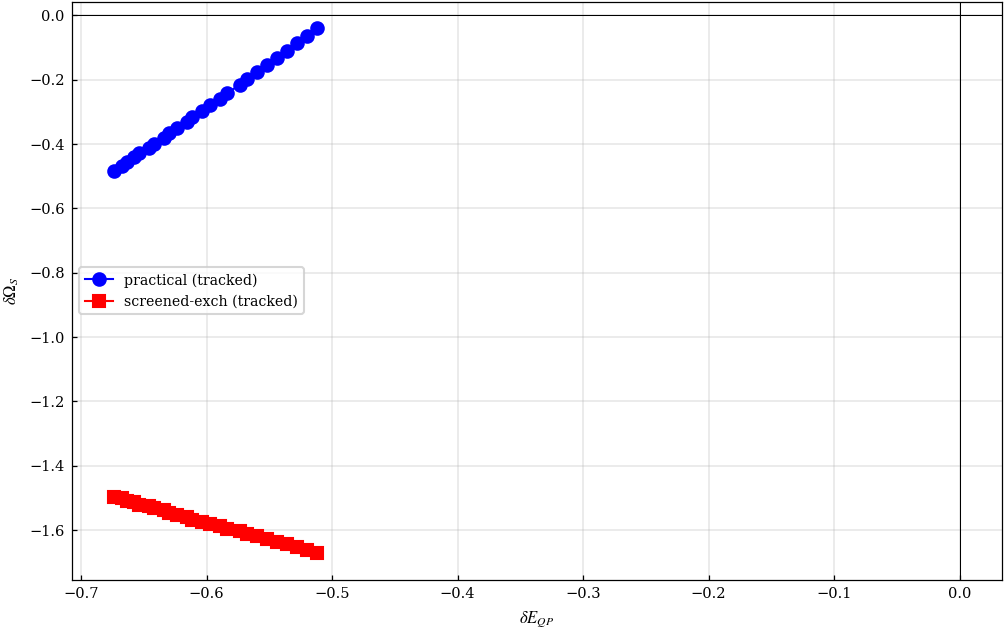

In [32]:
def scan_tracked(t, U, V, Delta, alphas):
    gap_ex, Om1_ex = get_exact_observables(t, U, V, Delta)
    v = np.array([[U, V], [V, U]], float)
    h_TB = np.array([[0.5*Delta, -t], [-t, -0.5*Delta]])
    eps_TB, P_TB = np.linalg.eigh(h_TB)
    rho_TB = np.outer(P_TB[:,0], P_TB[:,0])
    Sig_x_TB = -(rho_TB * v)
    out = []; prev = None
    for alpha in alphas:
        h0 = h_TB + alpha*Sig_x_TB
        eps, P = np.linalg.eigh(h0)
        rho = np.outer(P[:,0], P[:,0])
        SigHS = np.diag(U*np.diag(rho) + V*(rho[1,1]+rho[0,0]-np.diag(rho))) - rho*v
        dE = eps[1]-eps[0]; tr = P[:,0]*P[:,1]; M = np.outer(tr, tr)
        def epsR(w, eta=1e-8): return np.eye(2) - v @ (M*(1/(w-dE+1j*eta) - 1/(w+dE+1j*eta)))
        ws = np.linspace(dE+1e-4, dE+10, 300)
        fs = np.sign([np.real(np.linalg.det(epsR(w,1e-9))) for w in ws])
        ix = np.where(fs[:-1]*fs[1:] < 0)[0]
        if len(ix)==0: continue
        Om_p = brentq(lambda w: np.real(np.linalg.det(epsR(w,1e-9))), ws[ix[0]], ws[ix[0]+1])
        ddet = (np.real(np.linalg.det(epsR(Om_p+1e-5)))-np.real(np.linalg.det(epsR(Om_p-1e-5))))/2e-5
        Em = epsR(Om_p)
        R = np.real(v @ np.array([[Em[1,1],-Em[0,1]],[-Em[1,0],Em[0,0]]])/ddet)
        R0 = np.outer(P[:,0],P[:,0])*R.T; R1 = np.outer(P[:,1],P[:,1])*R.T
        def Sig(w):
            return SigHS + R0/(w-eps[0]+Om_p+1j*1e-4) + R1/(w-eps[1]-Om_p+1j*1e-4)
        w_scan = np.linspace(-8, 8, 8001)
        dmin = np.array([np.min(np.linalg.svd(w*np.eye(2)-h_TB-Sig(w), compute_uv=False)) for w in w_scan])
        def find(thr):
            return sorted(w_scan[i] for i in range(1,len(w_scan)-1)
                          if dmin[i]<dmin[i-1] and dmin[i]<=dmin[i+1] and dmin[i]<thr)
        poles = find(1e-2) or find(3e-2) or find(1e-1)
        if len(poles) < 2: prev=None; continue
        if prev is None:
            c0 = 0.5*(SigHS[0,0]+SigHS[1,1])
            a,b = min(zip(poles[:-1],poles[1:]), key=lambda pr: abs(0.5*(pr[0]+pr[1])-c0))
        else:
            a,b = min(zip(poles[:-1],poles[1:]), key=lambda pr: (pr[0]-prev[0])**2+(pr[1]-prev[1])**2)
        prev = (a,b)
        gap_GW = b-a
        W0 = np.real(np.linalg.solve(epsR(0.0), v))
        D = (P[:,0]**2) @ W0 @ (P[:,1]**2)
        Kp = 2*(tr@v@tr) - D; Ks = 2*(tr@W0@tr) - D
        out.append(dict(alpha=alpha, a=a, b=b, npoles=len(poles), gap_GW=gap_GW,
                        dE=gap_GW-gap_ex,
                        dOm_p=gap_GW+Kp-Om1_ex, dOm_s=gap_GW+Ks-Om1_ex))
    return out

# --- Regression check FIRST---
r0 = scan_tracked(1.0, 4.0, 0.0, 0.5, [0.0])
print('REGRESSION (4,0,0.5), a=0: dE=%.3f (target -0.875), dOm_p=%.3f (target -0.094)'
      % (r0[0]['dE'], r0[0]['dOm_p']))

# --- Tracked scan at V=1 ---
alphas = np.linspace(0,1,25)
res = scan_tracked(1.0, 4.0, 1.0, 0.5, alphas)
print('alpha coverage:', [round(r['alpha'],2) for r in res])
dE  = np.array([r['dE'] for r in res]);  dp = np.array([r['dOm_p'] for r in res])
ds = np.array([r['dOm_s'] for r in res])
mL, mR = dE < -0.5, dE > 0.5
if mL.sum()>2 and mR.sum()>2:
    print('practical local slopes: left %.2f  right %.2f  global %.2f' % (
        np.polyfit(dE[mL],dp[mL],1)[0], np.polyfit(dE[mR],dp[mR],1)[0], np.polyfit(dE,dp,1)[0]))
plt.figure(figsize=(8,5))
plt.plot(dE, dp, 'o-', color='b', label='practical (tracked)')
plt.plot(dE, ds, 's-', color='r', label='screened-exch (tracked)')
plt.axhline(0,color='k',lw=.5); plt.axvline(0,color='k',lw=.5)
plt.xlabel(r'$\delta E_{QP}$'); plt.ylabel(r'$\delta\Omega_S$'); plt.legend(); plt.grid(alpha=.3)
plt.show()

In [33]:
# add to the dict in scan_tracked:  a=a, b=b, npoles=len(poles), gap_GW=gap_GW
for V in (0.0, 1.0):
    res = scan_tracked(1.0, 4.0, V, 0.5, np.linspace(0, 1, 13))
    print(f"V={V}")
    for r in res:
        print(f"a={r['alpha']:.2f} poles=({r['a']:.3f},{r['b']:.3f}) n={r['npoles']} "
              f"gapGW={r['gap_GW']:.3f} dE={r['dE']:.3f} dOm_p={r['dOm_p']:.3f} dOm_s={r['dOm_s']:.3f}")

V=0.0
a=0.00 poles=(-1.370,1.370) n=2 gapGW=2.740 dE=-0.871 dOm_p=-0.090 dOm_s=-2.523
a=0.08 poles=(-1.370,1.348) n=4 gapGW=2.718 dE=-0.893 dOm_p=-0.173 dOm_s=-2.531
a=0.17 poles=(-1.370,1.328) n=3 gapGW=2.698 dE=-0.913 dOm_p=-0.260 dOm_s=-2.536
a=0.25 poles=(-1.370,1.306) n=3 gapGW=2.676 dE=-0.935 dOm_p=-0.353 dOm_s=-2.541
a=0.33 poles=(-1.370,1.284) n=2 gapGW=2.654 dE=-0.957 dOm_p=-0.450 dOm_s=-2.545
a=0.42 poles=(-1.370,1.262) n=3 gapGW=2.632 dE=-0.979 dOm_p=-0.548 dOm_s=-2.548
a=0.50 poles=(-1.368,1.240) n=4 gapGW=2.608 dE=-1.003 dOm_p=-0.650 dOm_s=-2.551
a=0.58 poles=(-1.368,1.218) n=3 gapGW=2.586 dE=-1.025 dOm_p=-0.749 dOm_s=-2.552
a=0.67 poles=(-1.368,1.196) n=3 gapGW=2.564 dE=-1.047 dOm_p=-0.847 dOm_s=-2.552
a=0.75 poles=(-1.366,1.174) n=4 gapGW=2.540 dE=-1.071 dOm_p=-0.946 dOm_s=-2.554
a=0.83 poles=(-1.364,1.152) n=4 gapGW=2.516 dE=-1.095 dOm_p=-1.043 dOm_s=-2.555
a=0.92 poles=(-1.364,1.130) n=3 gapGW=2.494 dE=-1.117 dOm_p=-1.136 dOm_s=-2.554
a=1.00 poles=(-1.362,1.108) n=3 ga

In [34]:
for V in (0.0, 1.0):
    alphas = np.linspace(0, 1, 13)
    res = scan_tracked(1.0, 4.0, V, 0.5, alphas)
    got = {round(r['alpha'], 4) for r in res}
    print(f"V={V}  points={len(res)}/{len(alphas)}  "
          f"missing={[round(a, 3) for a in alphas if round(a, 4) not in got]}")
    for r in res:
        print(f"a={r['alpha']:.2f} poles=({r['a']:.3f},{r['b']:.3f}) n={r['npoles']} "
              f"gapGW={r['gap_GW']:.3f} dE={r['dE']:.3f} "
              f"dOm_p={r['dOm_p']:.3f} dOm_s={r['dOm_s']:.3f}")

V=0.0  points=13/13  missing=[]
a=0.00 poles=(-1.370,1.370) n=2 gapGW=2.740 dE=-0.871 dOm_p=-0.090 dOm_s=-2.523
a=0.08 poles=(-1.370,1.348) n=4 gapGW=2.718 dE=-0.893 dOm_p=-0.173 dOm_s=-2.531
a=0.17 poles=(-1.370,1.328) n=3 gapGW=2.698 dE=-0.913 dOm_p=-0.260 dOm_s=-2.536
a=0.25 poles=(-1.370,1.306) n=3 gapGW=2.676 dE=-0.935 dOm_p=-0.353 dOm_s=-2.541
a=0.33 poles=(-1.370,1.284) n=2 gapGW=2.654 dE=-0.957 dOm_p=-0.450 dOm_s=-2.545
a=0.42 poles=(-1.370,1.262) n=3 gapGW=2.632 dE=-0.979 dOm_p=-0.548 dOm_s=-2.548
a=0.50 poles=(-1.368,1.240) n=4 gapGW=2.608 dE=-1.003 dOm_p=-0.650 dOm_s=-2.551
a=0.58 poles=(-1.368,1.218) n=3 gapGW=2.586 dE=-1.025 dOm_p=-0.749 dOm_s=-2.552
a=0.67 poles=(-1.368,1.196) n=3 gapGW=2.564 dE=-1.047 dOm_p=-0.847 dOm_s=-2.552
a=0.75 poles=(-1.366,1.174) n=4 gapGW=2.540 dE=-1.071 dOm_p=-0.946 dOm_s=-2.554
a=0.83 poles=(-1.364,1.152) n=4 gapGW=2.516 dE=-1.095 dOm_p=-1.043 dOm_s=-2.555
a=0.92 poles=(-1.364,1.130) n=3 gapGW=2.494 dE=-1.117 dOm_p=-1.136 dOm_s=-2.554
a=1.00 p